# Computational Probability & Statistics

This notebook covers the code-oriented problem sets at my Computational Prrobability & Statistics course. I plan on adding the theoretical problems later on using LaTeX, eventually.

In [1]:
%pip -q install matplotlib
%pip -q  install scipy
%pip -q install numpy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## PSet 1: Introduction to Probability


In [2]:
import scipy
import matplotlib.pyplot as plt
import numpy as np

**Exercise 26.** [Wasserman 2003 (1.10.21)]  
Una moneda tiene probabilidad $p$ de salir cara. Si se lanza muchas veces, esperamos que la proporción de caras se acerque a $p$. Considere $p = 0.3$ y simule $n$ lanzamientos, con $n = 1, \dots, 1000$. Grafique la proporción de caras en función del número de lanzamientos. Repita con $p = 0.03$.

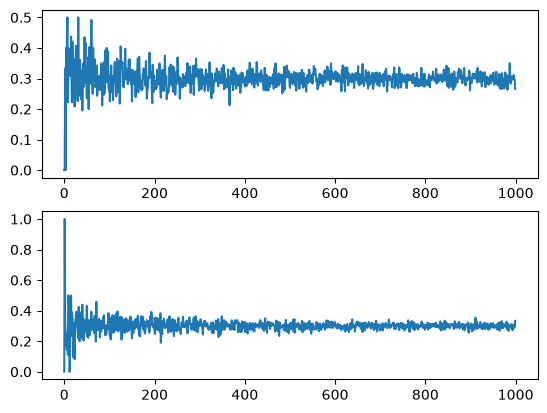

In [3]:
from scipy.stats import binom

heads_proportion = {0.3: [],
                    0.03:[]}

for i in range(1,1001):
    heads_proportion[0.3].append(binom.rvs(n=i,p=0.3)/i)
    heads_proportion[0.03].append(binom.rvs(n=i,p=0.3)/i)


experiment_count = np.arange(1000)

fig, (ax1,ax2) = plt.subplots(2)
ax1.plot(experiment_count, heads_proportion[0.3])
ax2.plot(experiment_count, heads_proportion[0.03])
plt.show()



**Ejercicio 27.** [Wasserman 2003 (1.10.22)]  
Suponga que lanzamos una moneda $n$ veces, con probabilidad $p$ de salir cara. Sea $X$ el número de caras. La intuición sugiere que, si $n$ es grande, $X$ debería estar cerca de $np$. Simule este experimento muchas veces (pruebe con $p = 0.3$ y $n = 10, 100$ y $1000$) y promedie los valores obtenidos de $X$ en cada caso. Compare dichos promedios con $np$.

In [4]:
head_counts = {10:0,
               100:0,
               1000:0
                }

heads_proportion = {10:[],
               100:[],
               1000:[]
                }

for n in [10,100,1000]:
    head_counts[n] = binom.rvs(n=n,p=0.3)
    heads_proportion[n].append(head_counts[n]/n)

for n in [10,100,1000]:
    print(f"(n={n},p=0.3) Expected: 3  Actual: {heads_proportion[n][0]}\n")

(n=10,p=0.3) Expected: 3  Actual: 0.4

(n=100,p=0.3) Expected: 3  Actual: 0.28

(n=1000,p=0.3) Expected: 3  Actual: 0.305



**Ejercicio 28.** [Wasserman 2003 (1.10.23)]  
Suponga que lanzamos un dado justo. Sean $A = \{2, 4, 6\}$ y $B = \{1, 2, 3, 4\}$. Entonces $P(A) = 1/2$, $P(B) = 2/3$, $P(A \cap B) = 1/3$, y se verifica que $P(A \cap B) = P(A)P(B)$, por lo tanto $A$ y $B$ son independientes. Simule lanzamientos y calcule frecuencias relativas $\hat{P}(A)$, $\hat{P}(B)$ y $\hat{P}(A \cap B)$ para verificar esta relación. Luego, busque dos eventos que no sean independientes, calcule nuevamente esas frecuencias y compare con los valores teóricos. Interprete los resultados.

In [5]:
from scipy.stats import randint #Scipy's discrete uniform is randint, not very intuitive in my opinion but ok

A = {2,4,6}
B = {1,2,3,4}
AnB = {2,4}

A_count, B_count, AnB_count = 0,0,0

for _ in range(6000):
    landing_side = randint.rvs(1,7)
    if landing_side in A: A_count+=1
    if landing_side in B: B_count+=1
    if landing_side in AnB: AnB_count+=1

print(f"Relative frequencies: \nP(A)={'{0:.2g}'.format(A_count/6000)}\nP(B)={'{0:.2g}'.format(B_count/6000)}\nP(AnB)={'{0:.2g}'.format(AnB_count/6000)}")



Relative frequencies: 
P(A)=0.51
P(B)=0.67
P(AnB)=0.34


**Ejercicio 29 (Continuación)** [De paseo por el casino de Monte Carlo en 1913]  
a) Cuente la cantidad de veces que ocurrieron 5 caras consecutivas. Compare con la cantidad de veces que ocurrió la siguiente secuencia específica: $\text{CXCCX}$ (o casi cualquier otra). ¿Son similares?  
b) Cuente la cantidad de veces que una secuencia de 5 caras consecutivas fue seguida por una ceca. Idem pero seguida por otra cara. ¿Son similares?  
c) “La probabilidad de 6 caras consecutivas es mucho menor que la de 5 caras consecutivas. Por eso si veo 5 caras seguidas en la siguiente tirada apuesto a cruz”. Explique cuál es la lógica en esta falla. Defina claramente el experimento, el espacio muestral y el evento por el cual está apostando.  
d) ¿Qué pasa con el análisis si permite superposición al agrupar de a 5 tiradas?

In [6]:
allHeadsCount = 0
specificPatternCount = 0

for _ in range(1000):
    pattern = [0,0,0,0,0]    
    for i in range(5):
        pattern[i] = binom.rvs(n=1,p=0.5)

    if (pattern == [1,1,1,1,1]):
        allHeadsCount += 1
    if (pattern == [1,0,1,1,0]):
        specificPatternCount += 1
    
print(allHeadsCount, specificPatternCount)

31 29


**Ejercicio 30.** [(Equilibrando una moneda desequilibrada$^2$)]  
Una moneda desequilibrada tiene probabilidad $p < 0.5$ de salir cara.

a) Elija un valor de $p$ y simule $n = 100000$ lanzamientos. Grafique la cantidad de caras y cruces, compare con los valores esperados $np$ y $n(1 - p)$.  


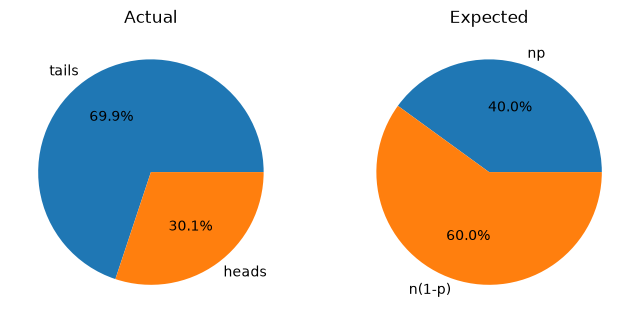

In [55]:
from scipy.stats import bernoulli

fig, axs = plt.subplots(1,2, figsize=(8, 4))

p = 0.3

x = [0,0]

for _ in range(100000):
    res = (bernoulli.rvs(p))
    x[res] += 1

axs[0].pie(x, labels=["tails","heads"], autopct='%1.1f%%')
axs[0].set_title("Actual")
axs[1].pie([100000*0.4,100000*(1-0.4)], labels=["np","n(1-p)"], autopct='%1.1f%%')
axs[1].set_title("Expected")
plt.show()

b) Tome la secuencia de lanzamientos de recién y agrupe los lanzamientos consecutivos de a pares, como si el experimento en realidad hubiera sido “arroje dos veces una moneda”. ¿Cuáles son los eventos posibles? Grafique la cantidad de cada tipo y note que dos de ellos son prácticamente equiprobables. ¿A qué se debe? ¿Depende del valor de $p$? Defina un algoritmo apropiado para obtener resultados equiprobables utilizando este fenómeno.  

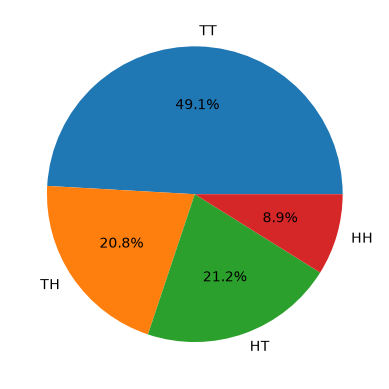

In [47]:
x = [0,0,0,0]

for _ in range(50000):
    throw1 = (bernoulli.rvs(p))
    throw2 = (bernoulli.rvs(p))

    x[throw1 * 2 + throw2] += 1

plt.pie(x, labels=["TT","TH","HT","HH"], autopct='%1.1f%%')

plt.show()

They are equally odd due to the fact that the probability of each event {tt,th,ht,hh} are calculated by x*y (where x and y are independent events with odds 0.4 when heads and 0.6 when tails). The resulting probability table:

| | h | t |
|---|---|---|
| **h** | $(0.4)^2$ | $0.4*0.6$ |
| **t** | $0.6*0.4$ | $(0.6)^2$ |

c) Calcule el número promedio de lanzamientos entre ocurrencias consecutivas de cualquiera de los eventos equiprobables. Repita para muchos valores de $0 < p < 0.5$ y grafique en función de $p$. Discuta la eficiencia del algoritmo.

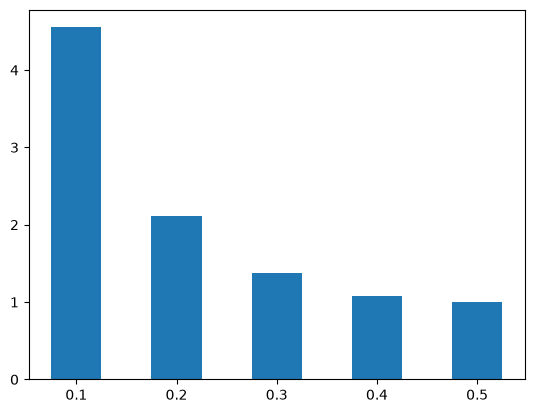

In [51]:
from scipy.stats import bernoulli
n = 50000

ps = [0.1,0.2,0.3,0.4,0.5]
samples = [[],[],[],[],[]]

contador = 0

for j in range(1,6):
    p = j/10
    sample = samples[j-1]

    for _ in range(n):
        throw1 = (bernoulli.rvs(p))
        throw2 = (bernoulli.rvs(p))

        if((throw1 and (not throw2)) or (not throw1 and throw2)):
            sample.append(contador)
            contador = 0
        else:
            contador+=1

for j in range(5):
    samples[j] = np.sum(samples[j]) / len(samples[j])

plt.bar(ps,samples, width=0.05)
plt.show()

## PSet 2: Random Variables

**Exercise 28. [ProbEst 2024, guide 2 (4,6)]**  
Define a function that, given two vectors $x = (x_1, \dots, x_n)$ and $p = (p_1, \dots, p_n)$, estimates the expectation and variance of the discrete random variable that takes values $x_1, \dots, x_n$ with probabilities $p_1, \dots, p_n$ respectively.


For this we use 

$$E(X) = \sum_{x_i \in X}{x_i f(x_i)} = \sum_{x_i \in X}{x_i P(X=x_i)} = \sum_{x_i \in X}{x_i p_i} $$
$$Var(X) = E(X²) - E(X)² = \frac{\sum_{x_i \in X}{x_i²}}{n-1} - E(X)²$$

In [25]:
def f(x, p):
    expectation = np.sum(x*p)
    variance =  np.sum(x**2)/n-1 - expectation**2 
    return expectation, variance 

**Exercise 29. [some proofs in Casella Berger 2024 (sections 3.2 and 3.3)]**  
Make histograms of large samples and graphically verify the similarity of the following distributions:

1. $X \sim \text{Bin}(n, p)$ versus $X \sim \text{Poisson}(np)$ in the case of large $n$ and small $p$.
2. $X \sim \text{Bin}(n, p)$ versus $X \sim \text{Normal}(np, np(1 - p))$ in the case of large $n$ and $p$ not close to $0$ or $1$.
3. $X \sim \text{Gamma}(\alpha, \beta)$ versus $X \sim \text{Normal}(\alpha, \beta)$ versus $X \sim \text{Normal}(\alpha/\beta, \alpha/\beta^2)$ in the case of $\alpha \gg \beta$.
4. $X \sim \text{Student}(n)$ versus $X \sim \text{Normal}(0, 1)$ in the case of large $n$.



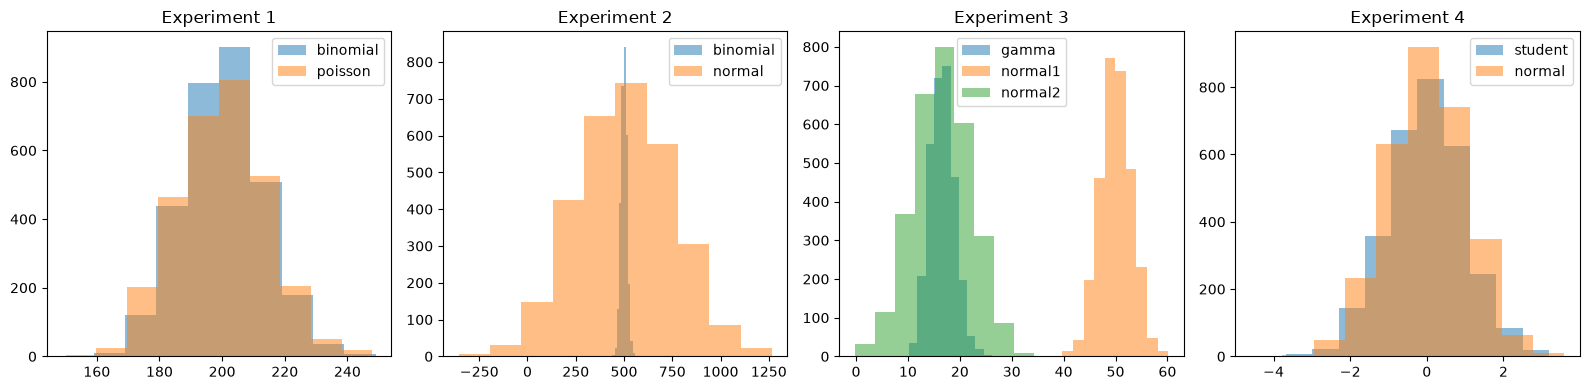

In [54]:
from scipy.stats import binom, poisson, norm, gamma, t


experiments = {
    "experiment_1": {"binomial": [], "poisson": []},
    "experiment_2": {"binomial": [], "normal": []},
    "experiment_3": {"gamma": [], "normal1": [], "normal2": []},
    "experiment_4": {"student": [], "normal": []}
}

n = 3000


fig, axs = plt.subplots(1, 4, figsize=(16, 4))

for _ in range(n):
    experiments["experiment_1"]["binomial"].append(binom.rvs(1000, 0.2))
    experiments["experiment_1"]["poisson"].append(poisson.rvs(200))

    experiments["experiment_2"]["binomial"].append(binom.rvs(1000, 0.5))
    experiments["experiment_2"]["normal"].append(norm.rvs(500, 500 * 0.5))

    experiments["experiment_3"]["gamma"].append(gamma.rvs(50, scale=1/3))
    experiments["experiment_3"]["normal1"].append(norm.rvs(50, 3))
    experiments["experiment_3"]["normal2"].append(norm.rvs(50/3, 50/9))

    experiments["experiment_4"]["student"].append(t.rvs(n))
    experiments["experiment_4"]["normal"].append(norm.rvs(0, 1))


exp_values = list(experiments.values())

for i, exp_dict in enumerate(exp_values):
    for dist_name, data in exp_dict.items():
        
        axs[i].hist(data, alpha=0.5, label=dist_name)
    
    axs[i].legend()
    axs[i].set_title(f"Experiment {i + 1}")

plt.tight_layout()
plt.show()

**Exercise 30. [ProbEst 2024, guide 3 (25)]**  
Transformation of variables. Plot the result as a histogram and compare with the theoretical distribution.

a) Using Exercise 17 part a), generate a random variable with distribution $\text{U}(3, 8)$ from a $\text{U}(0, 1)$.  
b) Using Exercise 17 part d), generate a random variable with distribution $\text{Exp}(10)$ from a $\text{U}(0, 1)$.  
c) Generate a random variable with the following discrete uniform distribution: $p_X(k) = \frac{1}{100}$ with $k = 0, 1, \dots, 99$ from a $\text{U}(0, 1)$.  
d) Generate a random variable with distribution $\text{Bin}(1, 1/3)$ from a $\text{U}(0, 1)$.  
e) Generate a random variable with distribution $\text{Poisson}(5)$ from a $\text{U}(0, 1)$.  

**Exercise 31. [Wasserman 2003 (2.14) (18)]**  
Let $X \sim N(3, 16)$. Solve the following using a numerical integrator.

a) Calculate $P(X < 7)$; $P(X > -2)$; $P(0 \le X < 4)$.  
b) Find $x$ such that $P(X > x) = 0.05$. Find $x$ such that $P(|X| > |x|) = 0.05$.  

Alternatively, how would you solve it if you had a sample of $n = 10000$ data points?

## PSet 3: Distribuciones Conjuntas

### Ejercicio 22. [Teórica (ley de los grandes números y teorema del límite central)]

Determine gráficamente la validez de lo siguiente. En todos los casos, para comparar histogramas superpuestos es mejor graficarlos con puntos unidos por segmentos (en vez de columnas).

**a)** Que a mayor tamaño de muestra mejor representada la distribución subyacente. *Sugerencia:* genere muestras de tamaño creciente de variables aleatorias provenientes de diferentes distribuciones conocidas (Uniforme, Normal, Binomial, Poisson, etc.) y grafique los histogramas.

**b) (Ley de los grandes números)** Que a partir de cierta cantidad de datos la media muestral y la desviación estándar muestral prácticamente no cambian con el tamaño de la muestra. (¿Pero qué pasa con la distribución de Cauchy?) Compare con el valor medio y la desviación estándar de la distribución subyacente.

**c) (Teorema del límite central)** Que la distribución de valores medios de muestras de un dado tamaño (grande) para cualquier distribución subyacente es aproximadamente normal. *Sugerencia:* con un renglón para cada distribución, en la columna 1 grafique la función teórica de densidad de probabilidad subyacente; en la columna 2 el histograma de 10000 medias muestrales con tamaño de muestra $n = 100$. (¿Pero qué pasa con la distribución de Cauchy?)

**d) (Forma de la distribución de medias muestrales)** Que la forma de la distribución de medias muestrales es similar a la distribución subyacente si el tamaño de muestra es chico, pero se parece cada vez más a una normal si el tamaño de muestra es grande. *Sugerencia:* elija una distribución y grafique en dos paneles: a la izquierda la distribución teórica subyacente; a la derecha, superpuestos, un histograma de 10000 datos provenientes de la distribución (o sea tamaño de muestra $n = 1$), un histograma de 10000 medias muestrales con tamaño de muestra $n = 2$, un histograma similar pero con tamaño de muestra $n = 5$, ídem con $n = 10$ y $n = 20$. (¿Pero qué pasa con la distribución de Cauchy?)

**e) (Desviación estándar de la distribución de medias muestrales)** Que el ancho de la distribución de medias muestrales disminuye al aumentar el tamaño de la muestra. *Sugerencia:* elija una distribución cualquiera y calcule el histograma de 10000 medias muestrales para cada tamaño de muestra $n = 10, 20, 50, 100$. Grafique los histogramas superpuestos y compare. (¿Pero qué pasa con la distribución de Cauchy?) Compare con el ítem b.

## PSet 4: Inferencia puntual e intervalos de confianza

### Ejercicio 21. [Teórica (estimadores insesgados de mínima varianza; relacionado al ejercicio 7)]

Elija una distribución de su preferencia con valor medio $\mu$ y varianza $\sigma^2$. Genere $N$ muestras $M_j = \{X_1, \dots, X_n\}$ ($1 < j < N$, con $N$ grande pero $n$ no tanto, por ejemplo $N = 1000$ y $n = 5$).

**a)** Considere los siguientes estimadores para el valor medio: 
- $\hat{\mu}_1 = \bar{X}$ (media muestral);
- $\hat{\mu}_2 = (X_1 + X_2) / 2$;
- $\hat{\mu}_3 = X_1$.

Calcule el histograma de los $N$ valores de cada estimador y grafíquelos superpuestos. ¿Cuál es el estimador menos variable?

**b)** Suponga que tiene una sola muestra, es decir un solo valor de cada estimador (como ocurre normalmente). ¿Qué estimador elegiría?



### Ejercicio 22. [Teórica (compromiso sesgo-varianza; relacionado al ejercicio 19)]

Elija una distribución de su preferencia con valor medio $\mu$ y varianza $\sigma^2$. Genere $N$ muestras $M_j = \{X_1, \dots, X_n\}$ ($1 < j < N$, con $N$ grande pero $n$ no tanto, por ejemplo $N = 1000$ y $n = 5$).

**a)** Considere los siguientes estimadores para la varianza:
- $\hat{\sigma}^2 = \frac{1}{n} \sum (X_i - \bar{X})^2$ (EMV);
- $S^2 = \frac{1}{n-1} \sum (X_i - \bar{X})^2$ (varianza muestral).

Para cada estimador calcule el histograma de sus $N$ valores y grafíquelos superpuestos. ¿Cuál es el estimador menos sesgado? ¿Cuál es el menos variable?

**b)** Suponga que tiene una sola muestra, es decir un solo valor de cada estimador (como ocurre normalmente). ¿Qué estimador elegiría?







### Ejercicio 23. [Teórica (nivel de confianza, intervalo de confianza y cobertura)]

Supongamos que un cierto fenómeno natural o social produce valores aleatorios con una distribución subyacente $\text{Normal}(\mu, \sigma^2)$. El resultado de una medición (por ejemplo, una pequeña encuesta) es una muestra de 5 dichos valores.

En lo siguiente, elija valores para $\mu$ y $\sigma^2$ y repita el procedimiento para niveles de confianza $0.68$, $0.95$, $0.99$ ($\alpha = 0.32$, $0.05$, $0.01$, respectivamente).

**a)** Genere 1000 muestras diferentes; con cada muestra estime el valor medio subyacente $\mu$ calculando el valor medio muestral y suponiendo conocido $\sigma^2$; calcule el correspondiente intervalo de confianza para un nivel de confianza $1 - \alpha$.

**b)** En una recta numérica grafique el valor medio subyacente $\mu$ y todas las medias muestrales con sus intervalos de confianza (no superpuestos en la recta sino desplegados hacia arriba para que puedan apreciarse, como un sánguche de 98 capas). ¿Hay intervalos de confianza claramente lejos del valor subyacente?

**c)** Calcule la fracción de intervalos que incluyen al valor “real” $\mu$ subyacente. ¿Coincide aproximadamente con el valor de $1 - \alpha$? ¿Coincide con el valor esperado proveniente de una distribución binomial?

**d)** Suponga que desconoce la distribución subyacente y cuenta con una sola de las muestras (algo similar a la realidad). ¿Cuál de las muestras sería su caso?

**e)** ¿Dependen sus respuestas de que la distribución subyacente haya sido normal? Repita con una distribución de su preferencia. (¿Pero qué ocurre con la distribución de Cauchy?)


### Ejercicio 24. [Teórica (intervalos de confianza)]

Use un generador de números pseudoaleatorios gaussianos $\text{Normal}(\mu, \sigma^2)$ como distribución subyacente con $\mu = 10$ y $\sigma = 2$, para generar 1000 muestras $\{X_1, X_2, X_3\}$ de tamaño 3.

**a)** Para cada terna calcule los valores de:

$$\text{I) } Z = \frac{\sqrt{n}(\bar{X} - \mu)}{\sigma}$$

$$\text{II) } T = \frac{\sqrt{n}(\bar{X} - \mu)}{S}$$

$$\text{III) } C_2 = \frac{n s^2}{\sigma^2}$$

$$\text{IV) } C_3 = \frac{(n-1) S^2}{\sigma^2}$$

donde $S^2 = \frac{1}{n-1} \sum (X_i - \bar{X})^2$ es la varianza muestral (y $S = \sqrt{S^2}$ el desvío muestral), y $s^2 = \frac{1}{n} \sum (X_i - \mu)^2$ es el EMV de la varianza cuando $\mu$ es conocido. Confeccione un histograma normalizado para cada una de las cuatro variables, y superponga la correspondiente distribución teórica ($\text{Normal}(0, 1)$, $t_{n-1}$, $\chi^2_n$ y $\chi^2_{n-1}$, respectivamente; es decir, con $n = 3$: $t_2$, $\chi^2_3$ y $\chi^2_2$).

**b)** Para cada terna calcule los intervalos de confianza de nivel $95\,\%$ para:
- **I)** $\mu$ suponiendo que $\sigma^2$ es conocido;
- **II)** $\mu$ suponiendo que $\sigma^2$ es desconocido;
- **III)** $\sigma^2$ suponiendo que $\mu$ es conocido;
- **IV)** $\sigma^2$ suponiendo que $\mu$ es desconocido.

En cada caso calcule la cantidad de intervalos que incluyen el valor verdadero.

**c)** Los valores calculados en el ítem anterior corresponden aproximadamente al $95\,\%$ de los intervalos, pero no exactamente. Analice si las fluctuaciones son compatibles con una distribución binomial.

## PSet 5: Contraste de hipótesis, Comparaciones múltiples

### Ejercicio 6. [Teórica (comparaciones múltiples, v2)]

Cuando las comparaciones múltiples te penalizan demasiado.

Considere una situación como la del ejercicio 5, pero esta vez suponga un escenario de hipótesis nula falsa, es decir hay efecto verdadero: el medicamento reduce la temperatura en dos grados con respecto al valor previo. Por ejemplo, quiere decidir si las temperaturas individuales registradas en una muestra de $n$ personas disminuyeron significativamente y para esto simula la muestra con valores distribuidos según $\text{Normal}(\mu = -2^\circ, \sigma^2 = (1^\circ)^2)$. Penalice las comparaciones individuales ajustando el $\alpha$ por Bonferroni. Para $n = 1$ no tiene penalización y podría rechazar la hipótesis nula midiendo una sola persona. ¿Qué ocurre con los rechazos individuales a medida que mide y compara más personas?

*PD:* antes de apurarse a sacar conclusiones equivocadas recuerde que nunca sabe si está en el escenario de hipótesis nula verdadera o en el escenario de hipótesis nula falsa.




### Ejercicio 7. [Teórica (significancia y tamaño de efecto; ver discusión 2)]

Suponga que está midiendo el resultado de una intervención experimental donde se realiza un cambio en la interfaz de usuario para un grupo reducido de personas seleccionadas al azar y como resultado se mide la diferencia en el nivel de satisfacción.

Genere datos sintéticos para representar los escenarios mostrados en la figura. Suponga que la diferencia en el nivel de satisfacción tiene una distribución normal (ya sea porque las respuestas se obtienen por medio de un slider o porque se usan valores discretos pero en un rango grande $0\text{-}100$). Las barras gruesas y delgadas indican el intervalo de confianza del $90\,\%$ y del $95\,\%$, respectivamente. La hipótesis nula es que el cambio en el nivel de satisfacción es cero. Un cambio “trivial” en el nivel de satisfacción sería uno que se encuentre, por ejemplo entre $-10$ y $10$ y en ese caso no vale la pena implementar las modificaciones a gran escala (la flecha hacia la izquierda significa que el intervalo de confianza termina fuera de la figura).




### Ejercicio 8. [Teórica (distribución de los p-values)]

Construya una población de $N = 10000$ datos provenientes de una distribución normal $\text{Normal}(\mu, \sigma^2)$. Repártalos en $M = 1000$ muestras de tamaño $n = 10$ y calcule los $p\text{-values}$ correspondientes. Vamos a estudiar el contraste $H_0: \mu = 0$; $H_1: \mu > 0$.

**a)** Tome $\mu = 0, \sigma^2 = 1$ como representación de un escenario de hipótesis nula verdadera. ¿Qué distribución aproximada tienen los $p\text{-values}$?

**b)** Compare con un escenario de hipótesis nula falsa, por ejemplo eligiendo $\mu = 1, \sigma^2 = 1$. ¿Qué distribución tienen los $p\text{-values}$? ¿Cambia con el valor de $\mu$?

**c)** Ahora suponga una situación realista donde lo único que tiene es una de dichas muestras con $p\text{-value}$ muy chico, es decir que puede rechazar $H_0$. ¿Puede adivinar en qué escenario se encuentra? (Hipótesis nula verdadera, falso positivo vs. Hipótesis nula falsa, verdadero negativo) ¿Qué le dice esto sobre las malas interpretaciones del $p\text{-value}$?